# Week 5 - Transfer Learning
**Lab 5: Neural Networks, Convolutions, and Transfer Learning** | Project 2: Deep Learning Applications (Individual)
Introduction to Applied AI | BS 8th Semester | Department of Electronics

> Before running: Settings -> Accelerator **GPU T4**, Internet **On**. Add the dataset "Intel Image Classification" (puneet6060).
>
> Cells marked `___` need YOUR real numbers from YOUR run. Replace every blank before submitting.

## Part 1: The Data, and an Image as Numbers (10 min)
### Task 1.1: Imports, GPU check, and class counts

In [1]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


### Task 1.2: Look at the images, then at the numbers

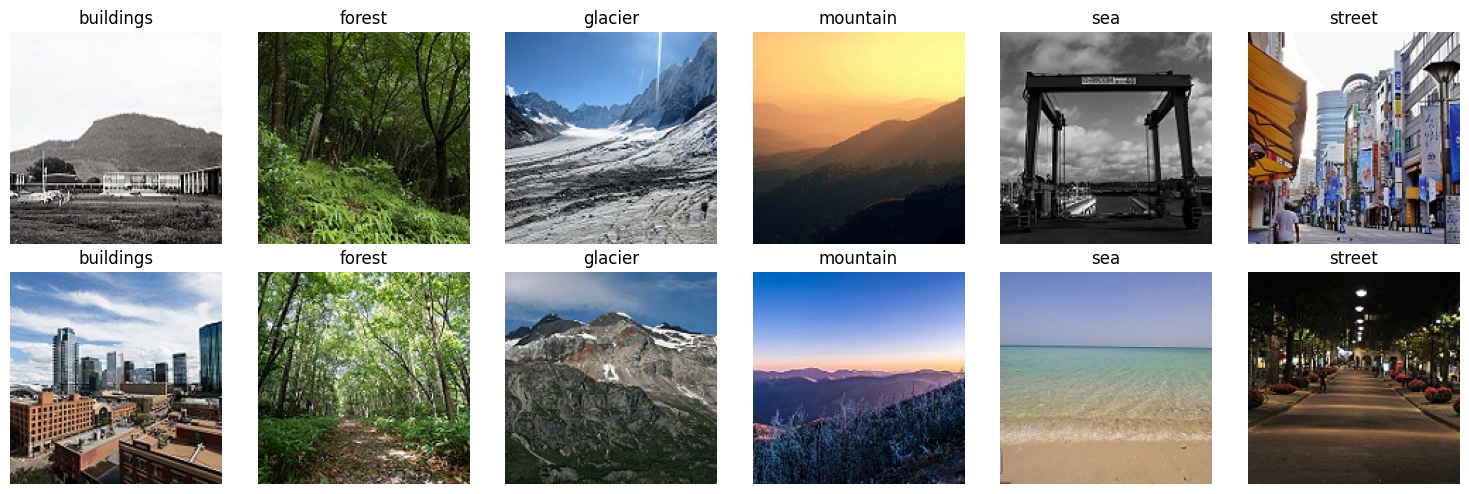

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [2]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### Write it (Part 1)
**GPU / data:** Device printed `___` (must be cuda). Classes: buildings, forest, glacier, mountain, sea, street. Class counts (copy from your output): train `___`, test `___`.

**Which classes look most similar by eye?** `___` and `___` (e.g. glacier vs mountain: both have snow, rock and sky; buildings vs street: both contain houses and roads).
**My prediction (to be checked in Part 6):** the model will confuse **`___` with `___`** the most.

**Image as numbers:** shape (H, W, C) = `___` (usually (150, 150, 3)), data type = `uint8`, value range = `0` to `255` (copy your printed min/max). An image is a 3-D tensor: height x width x 3 colour channels, each pixel intensity an integer 0-255.

## Part 2: Convolution and Parameters by Hand (10 min)
### Task 2.1: Reproduce the lecture's convolution
The 5 x 5 image has a vertical edge between columns 2 and 3. The kernel [-1, 0, 1] responds to left-to-right increases (slide 17).

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


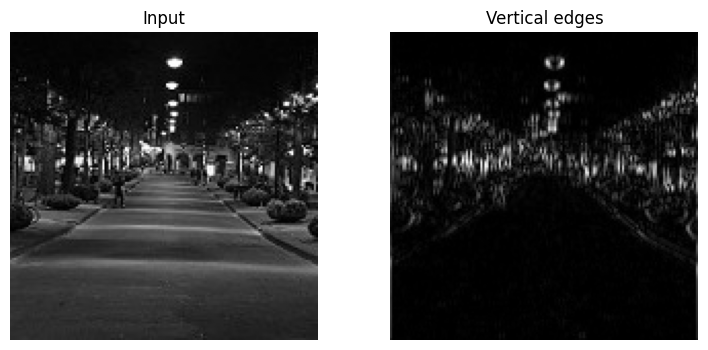

In [3]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

### Task 2.2: Why convolutions, in numbers

In [4]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64  : {count(conv):,} parameters')   # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')    # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64  : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


### Write it (Part 2)
**Convolution check:** the output is three rows of `[30, 30, 0]`. Example for the top-left window `[0,0,10]` in each row: (-1x0 + 0x0 + 1x10) x 3 rows = **30**; the last window `[10,10,10]` gives (-10 + 0 + 10) x 3 = **0** (flat region, no edge). So the kernel fires only where the intensity jumps from left to right.

**Parameter arithmetic** (formula: (K x K x C_in + 1) x C_out):
- Conv 3x3, 3 -> 64: (3 x 3 x 3 + 1) x 64 = 28 x 64 = **1,792**
- Dense 67,500 -> 512: 67,500 x 512 weights + 512 biases = 34,560,000 + 512 = **34,560,512**

**Ratio:** 34,560,512 / 1,792 = **19,286x** more parameters for the dense layer.

**Output sizes** ((W - K + 2P)/S + 1): stride 1 -> (224-3+2)/1+1 = 224, so (1, 64, 224, 224); stride 2 -> floor(223/2)+1 = 112, so (1, 64, 112, 112). 2x2 max pool halves H and W: (1, 3, 112, 112).

**Weight sharing (two sentences):** The same small kernel slides over every position, so a filter that detects e.g. an edge or a tree texture works wherever that pattern appears, giving translation-equivariant detection. The dense layer would have to learn the same pattern separately for every location, which needs far more weights and far more data.

## Part 3: Transforms and Data Loaders (15 min)
Pretrained ResNet expects 224 x 224 images normalized with ImageNet's mean and standard deviation (slide 28). Augmentation is applied to training images only (slide 30). We open the training folder twice, once with each transform, and split both views with the same random indices.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


**Why a validation set, when we already have a test set?** We use validation accuracy to choose the best epoch and to compare feature extraction with fine-tuning. The test set must play no part in any choice, exactly as in Week 3.

### Write it (Part 3)
**Split sizes (copy from your output):** `___` train | `___` val | `___` test. (Expected: 14,034 training images -> 15% = 2,105 val and 11,929 train; test = 3,000.)

**Wrong augmentation for this dataset:** a **vertical flip** (or a 180-degree rotation). Scenes have a fixed "up": sky above, ground/sea below. A flipped glacier or street would be an unrealistic image the model will never see at test time. (Horizontal flip is fine: a mountain mirrored left-right is still a mountain.)

**Wrong augmentation for handwritten digits:** a **horizontal/vertical flip or large rotation**. A flipped or rotated 6 looks like a 9 (and 2/5, 7 become non-digits), so the label would become wrong.

**Why augmentation only on training:** it adds variety so the model does not memorize; validation and test must be the clean, fixed images so that the measured accuracy is stable and honest.

## Part 4: The Training Loop and Feature Extraction (20 min)
### Task 4.1: A reusable training loop
forward pass, loss, backpropagation, and gradient step are the four boxes from slide 12. `fit()` keeps the model weights from the best validation epoch.

In [6]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                       # forward pass
            loss = F.cross_entropy(logits, yb)       # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                      # backpropagation
                optimizer.step()                     # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)    # keep the best validation epoch
    return best_acc

### Task 4.2: Freeze the body, train a new head

In [7]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 209MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (66s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (35s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (36s)
Best validation accuracy, feature extraction: 0.901


### Write it (Part 4)
**Trainable parameters:** `3,078` of `11,179,590` (about 11.2 million). 512 x 6 weights + 6 biases = 3,072 + 6 = **3,078**.

**Validation accuracy per epoch (feature extraction):** epoch 1 = `___`, epoch 2 = `___`, epoch 3 = `___`. Best = `___`.

**Why high accuracy with only 0.03% of parameters trained?** 3,078 / 11,179,590 = 0.0275%, about 0.03%. ResNet-18 was pretrained on 1.2 million ImageNet photos, so its frozen layers already compute a feature hierarchy: early layers detect edges and colours, middle layers textures and parts, late layers object/scene-level patterns (slide 20). Scene classes such as forest, sea and glacier are made of exactly these generic features, so the new linear head only has to learn how to weigh 512 ready-made features into 6 classes.

## Part 5: Fine-Tuning and Learning Curves (15 min)
### Task 5.1: Unfreeze layer4 with a smaller learning rate

In [8]:
for p in model.layer4.parameters():
    p.requires_grad = True                       # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},   # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])      # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.227 acc 0.926 (38s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.933 (38s)
epoch 3: train loss 0.124 acc 0.954 | val loss 0.219 acc 0.926 (38s)
Best validation accuracy, fine-tuned: 0.933


### Task 5.2: Plot the learning curves

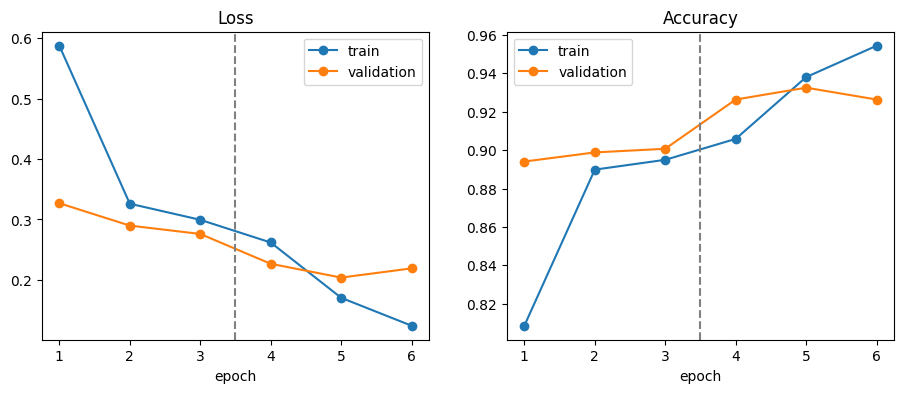

In [9]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')        # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

### Write it (Part 5)
**Trainable parameters now:** `8,396,806` (layer4 = 8,393,728 + fc = 3,078), about 8.4 million (copy your printed value).

**Did fine-tuning improve validation accuracy?** Feature extraction best = `___`; fine-tuned best = `___`; improvement = `___` percentage points. (Fill in from your run: typically a gain of a few points.)

**What the curves show:** epochs 1-3 (feature extraction): train/val loss `___`. After the dashed line (epochs 4-6, fine-tuning): train loss `___`, val loss `___`, val accuracy `___`. Describe in your own words what you see in your plot.

**Overfitting?** Check whether training loss keeps falling while validation loss rises. In my run: `___` (yes/no, with numbers). With only 3 fine-tuning epochs and augmentation, strong overfitting is normally not visible yet.

**Why training accuracy can be LOWER than validation accuracy:** training images are augmented (random crops, flips, colour jitter), so they are harder than the clean validation images. Also, training accuracy is averaged over the epoch while the weights are still changing, whereas validation accuracy is measured at the end of the epoch with the best weights, in eval mode.

## Part 6: Test Once, Then Study the Errors (15 min)
### Task 6.1: Test-set evaluation

Test accuracy: 0.934
              precision    recall  f1-score   support

   buildings      0.952     0.902     0.926       437
      forest      0.994     0.987     0.990       474
     glacier      0.921     0.866     0.893       553
    mountain      0.881     0.918     0.899       525
         sea      0.945     0.982     0.963       510
      street      0.925     0.956     0.940       501

    accuracy                          0.934      3000
   macro avg      0.936     0.935     0.935      3000
weighted avg      0.935     0.934     0.934      3000



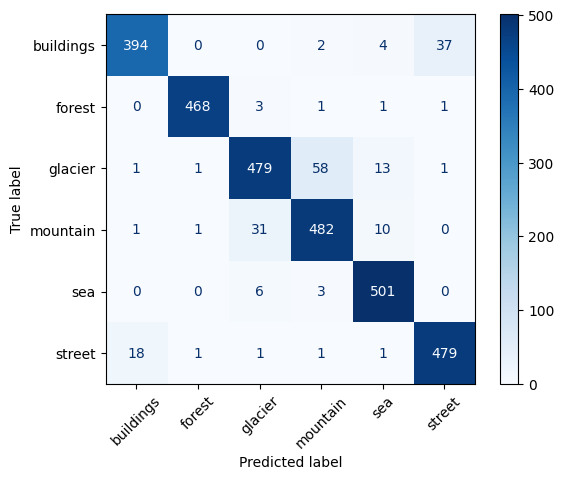

In [10]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

### Task 6.2: Error gallery

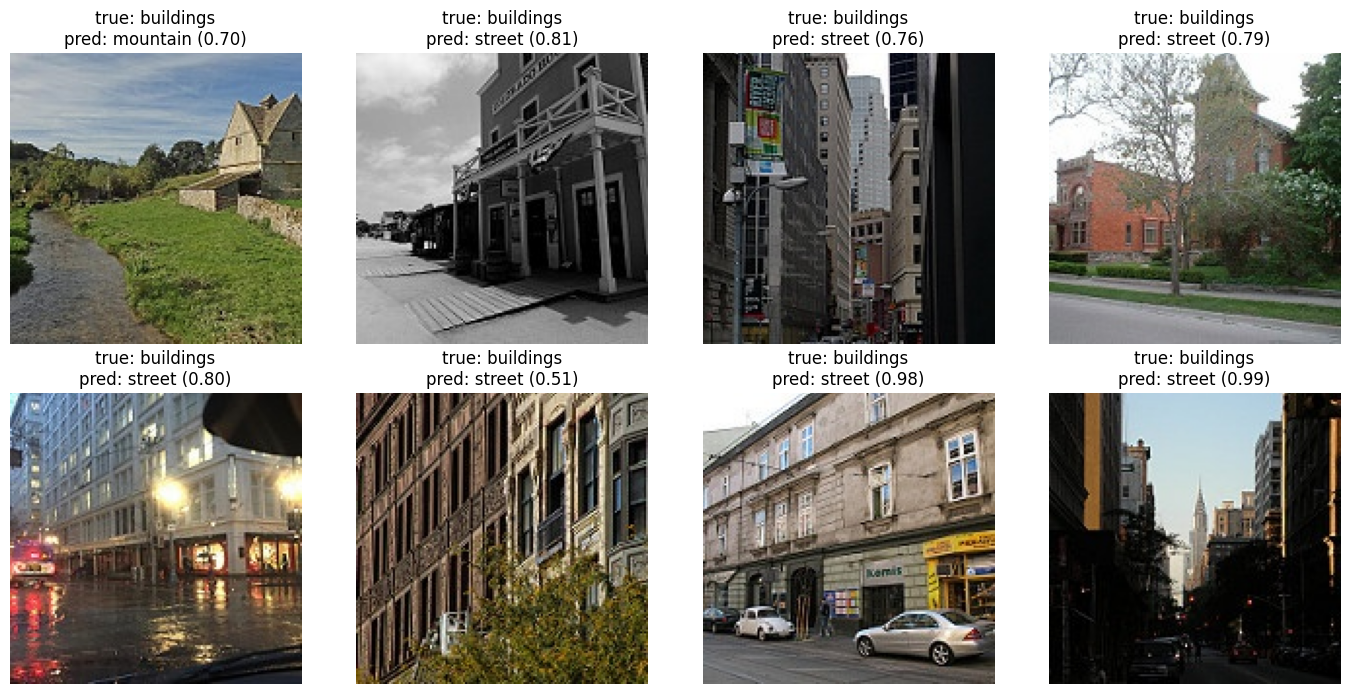

In [11]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

### Task 6.3: Inside one prediction
Softmax turns the six logits into probabilities that sum to 1 (slide 10).

In [12]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   7.96   probability 1.000
forest     logit  -9.29   probability 0.000
glacier    logit  -4.70   probability 0.000
mountain   logit  -5.06   probability 0.000
sea        logit  -4.56   probability 0.000
street     logit  -3.44   probability 0.000


### Write it (Part 6)
**Test accuracy (used once):** `___`.
**Two weakest classes by recall:** `___` (recall `___`) and `___` (recall `___`) - copy from the classification report.
**Most confused pair (largest off-diagonal in the confusion matrix):** `___` predicted as `___`, `___` images.
**My Part 1 prediction was** `___` (right / wrong) because `___`. (Glacier/mountain and buildings/street are the usual suspects.)

**Error gallery analysis (at least two errors; look at your own images):**
1. Image `___`: true `___`, predicted `___` (confidence `___`). Verdict: model wrong / label wrong / genuinely ambiguous, because `___`.
2. Image `___`: true `___`, predicted `___` (confidence `___`). Verdict: `___`, because `___`.

**Softmax on one image:** the six probabilities sum to 1; the largest logit gets the largest probability. For the true class `___` the model gave probability `___`. Compare with your hand-computed lecture table: same method, exp(logit) / sum of exp(logits).

## Part 7: Save and Share (5 min)

In [13]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


The file (about 45 MB) is under GitHub's 100 MB limit.

### Write it (Part 7) - README section (replace every bracket)
```
## Project 2, Week 5: Scene Classification with Transfer Learning
- Dataset: Intel Image Classification, 6 classes, [11,929] train / [3,000] test
- Model: ResNet-18 pretrained on ImageNet
- Feature extraction (3,078 trainable parameters): val accuracy [___]
- Fine-tuning layer4 (about 8.4M trainable): val accuracy [___]
- Test accuracy (used once): [___]; weakest class: [___], confused with [___]
- Most instructive error: [one sentence about a misclassified image]
- Next: my own domain in Week 6: [idea]

### Week 6 proposal
[One paragraph: the problem, who benefits, dataset link, number of classes and images.]
```

### LinkedIn post (replace every bracket with real numbers)
```
Week 5 of Applied AI: my first deep learning model.

I taught a network to recognise 6 kinds of scenes (forest,
glacier, sea, street...) with [__]% test accuracy.

The trick: transfer learning. ResNet-18 already learned edges,
textures and shapes from 1.2 million ImageNet photos. I trained
only 3,078 new parameters first, then fine-tuned the last block.

Its most common mistake: [class] vs [class]. Honestly, some of
those photos confuse me too. [screenshot of errors]

#DeepLearning #PyTorch #ComputerVision #LearningInPublic
```

## Check Your Understanding

**1. Why does a network without nonlinear activations collapse to a single linear layer?**
Each layer is a linear map: y = W2(W1 x + b1) + b2 = (W2 W1) x + (W2 b1 + b2) = W x + b. The product of matrices is just another matrix, so any depth equals one linear layer. Nonlinearities (ReLU) are what let depth add expressive power.

**2. Logits [3, 1, 0]: softmax probability of the first class?**
e^3 = 20.086, e^1 = 2.718, e^0 = 1. Sum = 23.804. P(class 1) = 20.086 / 23.804 = **0.844**.

**3. Parameters of a 3 x 3 convolution from 64 to 128 channels?**
(3 x 3 x 64 + 1) x 128 = 577 x 128 = **73,856**.

**4. Input 56 x 56, 3 x 3 conv, padding 1, stride 2: output size?**
(56 - 3 + 2 x 1) / 2 + 1 = 55/2 + 1 = 27.5 -> floor 27 + 1 = **28 x 28**.

**5. Why does a residual (skip) connection help gradients reach the early layers?**
A residual block computes y = F(x) + x, so dy/dx = dF/dx + 1. The "+1" is an identity path: gradients flow back directly through the shortcut without being shrunk by every layer's weights, which reduces vanishing gradients in deep networks.

**6. When would you train a CNN from scratch instead of transfer learning?**
When the data is very different from ImageNet (e.g. medical scans, spectrograms, multi-channel sensor/satellite data with a different number of channels), when you have a very large labelled dataset, or when you need a much smaller/custom architecture for deployment on constrained hardware.